In [1]:
print("始めます")

始めます


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

TRUE_EFFECT = -4.0

def simulate(n=1500, hidden_strength=0.0, seed=2026):
    rng = np.random.default_rng(seed)
    age = rng.normal(65, 10, n)
    size = np.clip(rng.normal(30, 8, n), 8, None)
    smoker = rng.binomial(1, 0.35, n)
    hidden = rng.normal(0, 1, n)
    logit = -0.2 - 0.06 * (age - 65) - 0.10 * (size - 30) + 0.4 * smoker + hidden_strength * hidden
    treat = rng.binomial(1, 1 / (1 + np.exp(-logit)))
    change = (0.10 * (age - 65) + 0.30 * (size - 30) + 2.0 * smoker
              + 2.0 * hidden_strength * hidden + TRUE_EFFECT * treat + rng.normal(0, 4, n))
    return pd.DataFrame({"age": age, "size": size, "smoker": smoker, "treat": treat, "change": change})

df = simulate()
print(df.groupby("treat").mean().round(2))
print("人数:", df["treat"].value_counts().to_dict())
naive = df.loc[df.treat == 1, "change"].mean() - df.loc[df.treat == 0, "change"].mean()
print(f"\n素朴な差（治療群 − 非治療群）: {naive:.2f} mm   ／ 真の効果: {TRUE_EFFECT} mm")

         age   size  smoker  change
treat                              
0      67.53  32.55     0.3    1.46
1      62.32  27.07     0.4   -4.33
人数: {1: 784, 0: 716}

素朴な差（治療群 − 非治療群）: -5.78 mm   ／ 真の効果: -4.0 mm


In [3]:
covs = ["age", "size", "smoker"]

def smd(data, col, weights=None):
    t, c = data[data.treat == 1][col], data[data.treat == 0][col]
    return (t.mean() - c.mean()) / np.sqrt((t.var() + c.var()) / 2)

before = pd.Series({c: smd(df, c) for c in covs})
print("マッチング前の SMD")
print(before.round(3))

マッチング前の SMD
age      -0.534
size     -0.721
smoker    0.220
dtype: float64


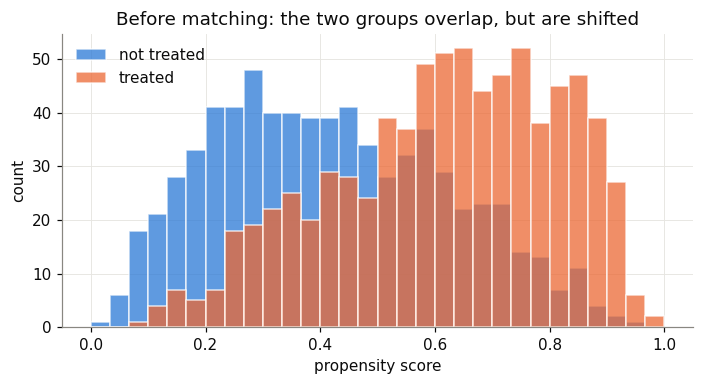

In [4]:
def add_ps(data):
    data = data.copy()
    model = LogisticRegression(C=1e6, max_iter=1000).fit(data[covs], data["treat"])
    data["ps"] = model.predict_proba(data[covs])[:, 1]
    data["logit_ps"] = np.log(data["ps"] / (1 - data["ps"]))
    return data

df = add_ps(df)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.linspace(0, 1, 31)
ax.hist(df.loc[df.treat == 0, "ps"], bins=bins, color=BLUE, alpha=0.75, edgecolor="white", label="not treated")
ax.hist(df.loc[df.treat == 1, "ps"], bins=bins, color=ORANGE, alpha=0.75, edgecolor="white", label="treated")
ax.set(xlabel="propensity score", ylabel="count", title="Before matching: the two groups overlap, but are shifted")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [5]:
def match_1to1(data, caliper_sd=0.2, seed=0):
    rng = np.random.default_rng(seed)
    caliper = caliper_sd * data["logit_ps"].std()
    treated = data.index[data.treat == 1].to_numpy()
    controls = data.index[data.treat == 0].to_numpy()
    c_logit = data.loc[controls, "logit_ps"].to_numpy()
    free = np.ones(len(controls), bool)
    pairs = []
    for t in rng.permutation(treated):
        dist = np.abs(c_logit - data.at[t, "logit_ps"])
        dist[~free] = np.inf
        j = dist.argmin()
        if dist[j] <= caliper:
            pairs.append((t, controls[j]))
            free[j] = False
    return pairs

pairs = match_1to1(df)
matched = df.loc[[i for p in pairs for i in p]]
print(f"治療群 {int((df.treat==1).sum())} 人のうち、組になれた人: {len(pairs)} 人")
print("マッチ後の人数:", matched["treat"].value_counts().to_dict())

治療群 784 人のうち、組になれた人: 467 人
マッチ後の人数: {1: 467, 0: 467}


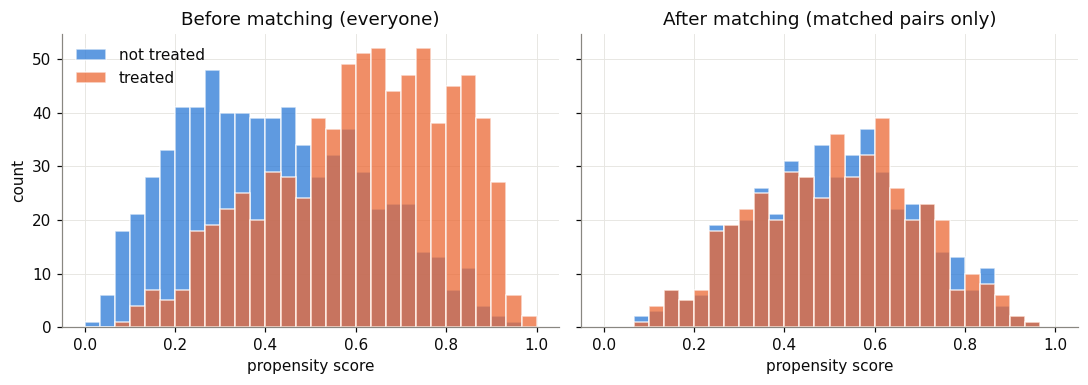

マッチング前: 傾向スコアの平均 非治療 0.419 / 治療 0.617, SMD = 0.994, 人数 1500
マッチング後: 傾向スコアの平均 非治療 0.513 / 治療 0.516, SMD = 0.016, 人数 934


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a_, d_, title in [(ax[0], df, "Before matching (everyone)"), (ax[1], matched, "After matching (matched pairs only)")]:
    a_.hist(d_.loc[d_.treat == 0, "ps"], bins=bins, color=BLUE, alpha=0.75, edgecolor="white", label="not treated")
    a_.hist(d_.loc[d_.treat == 1, "ps"], bins=bins, color=ORANGE, alpha=0.75, edgecolor="white", label="treated")
    a_.set(xlabel="propensity score", title=title)
ax[0].set_ylabel("count")
ax[0].legend(frameon=False)
plt.tight_layout(); plt.show()

for label_, d_ in [("マッチング前", df), ("マッチング後", matched)]:
    m_ = d_.groupby("treat")["ps"].mean()
    print(f"{label_}: 傾向スコアの平均 非治療 {m_[0]:.3f} / 治療 {m_[1]:.3f}, SMD = {smd(d_, 'ps'):.3f}, 人数 {len(d_)}")

        before  after
age     -0.534 -0.027
size    -0.721  0.016
smoker   0.220  0.027


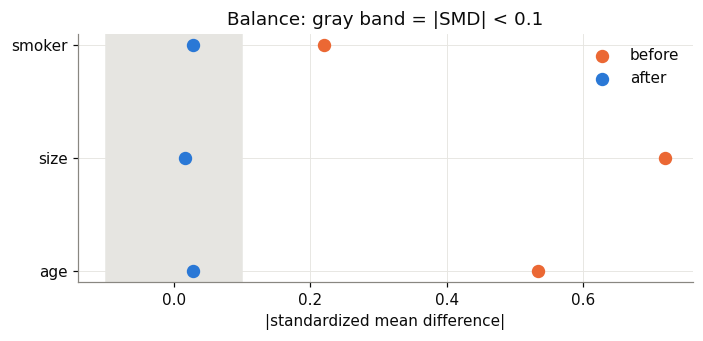

In [7]:
after = pd.Series({c: smd(matched, c) for c in covs})
print(pd.DataFrame({"before": before, "after": after}).round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
y = np.arange(len(covs))
ax.axvspan(-0.1, 0.1, color="#e6e5e1", zorder=0)
ax.scatter(before.abs()[covs], y, color=ORANGE, s=60, label="before", zorder=3)
ax.scatter(after.abs()[covs], y, color=BLUE, s=60, label="after", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(covs)
ax.set(xlabel="|standardized mean difference|", title="Balance: gray band = |SMD| < 0.1")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [8]:
est_matched = matched.loc[matched.treat == 1, "change"].mean() - matched.loc[matched.treat == 0, "change"].mean()
print(f"真の効果          : {TRUE_EFFECT:.2f} mm")
print(f"素朴な差          : {naive:.2f} mm")
print(f"マッチング後の差  : {est_matched:.2f} mm")


真の効果          : -4.00 mm
素朴な差          : -5.78 mm
マッチング後の差  : -3.97 mm


In [9]:
covs = ["age", "size", "smoker", "change"]
df_bad = add_ps(simulate())
pairs_bad = match_1to1(df_bad)
matched_bad = df_bad.loc[[i for p in pairs_bad for i in p]]
diff = (matched_bad.loc[matched_bad.treat == 1, "change"].mean()
        - matched_bad.loc[matched_bad.treat == 0, "change"].mean())
print("age の SMD:", round(smd(matched_bad, "age"), 3), "／ 効果の推定値:", round(diff, 2))

age の SMD: 0.004 ／ 効果の推定値: -0.05


In [10]:
covs = ["age", "size", "smoker"]
df = add_ps(simulate())
pairs = match_1to1(df)
matched = df.loc[[i for p in pairs for i in p]]
naive = df.loc[df.treat == 1, "change"].mean() - df.loc[df.treat == 0, "change"].mean()
est_matched = matched.loc[matched.treat == 1, "change"].mean() - matched.loc[matched.treat == 0, "change"].mean()
print(f"真の効果          : {TRUE_EFFECT:.2f} mm")
print(f"素朴な差          : {naive:.2f} mm")
print(f"マッチング後の差  : {est_matched:.2f} mm")

真の効果          : -4.00 mm
素朴な差          : -5.78 mm
マッチング後の差  : -3.97 mm


In [11]:
df2 = add_ps(simulate(hidden_strength=0.8))
pairs2 = match_1to1(df2)
m2 = df2.loc[[i for p in pairs2 for i in p]]
print("観測した背景の |SMD|（マッチ後）:", {c: round(float(abs(smd(m2, c))), 3) for c in covs})
est2 = m2.loc[m2.treat == 1, "change"].mean() - m2.loc[m2.treat == 0, "change"].mean()
naive2 = df2.loc[df2.treat == 1, "change"].mean() - df2.loc[df2.treat == 0, "change"].mean()
print(f"真の効果 {TRUE_EFFECT:.2f} mm")
print(f"測っていない因子があるとき: 素朴な差 {naive2:.2f} mm, マッチング後の差 {est2:.2f} mm")


観測した背景の |SMD|（マッチ後）: {'age': 0.017, 'size': 0.029, 'smoker': 0.004}
真の効果 -4.00 mm
測っていない因子があるとき: 素朴な差 -4.56 mm, マッチング後の差 -2.61 mm
